## Testing the sample generator

In [ ]:
if False:
    import os
    os.environ["QUANTDATA_CACHE_MODE"] = "off" # turns off global cache mode; good for testing, but do not use in general.

%load_ext autoreload
%autoreload 1

%aimport quantdata
%aimport quantdata.massive.client
%aimport quantdata.massive.processing
%aimport quantdata.ncde.voluvol.generate

from datetime import date
from quantdata.ncde.voluvol.generate import ExperimentScope, ExperimentLoader, DateRange

def load():
    scope = ExperimentScope(
        tickers = ['AAPL', 'MSFT' ],
        date_range = DateRange( date(2025, 1, 1), date(2025, 1, 6) ),  # will use only business days
        forecast_horizon_min = 15 # 15 minutes

    )

    # set cache mode to "update" to force update of top level time series (e.g. not the raw data, but generate_ticker_day())
    return ExperimentLoader(scope, override_cache_mode=None ) 

experiment = load()
print(f"Experiment has {len(experiment)} samples.")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
00: Generated data for all tickers for 3 days from 2025-01-02 to 2025-01-06 excluding half days. This took 2s.
Experiment has 6 samples.


In [3]:
from cdxcore.util import fmt_big_byte_number
from cdxcore.verbose import Context
from collections.abc import Mapping

def print_sample(sample_id):

    sample_id = experiment.get_sample_id(sample_id)
    sample    = experiment[sample_id]

    verbose = Context.all

    def prnt(x, level=1):
        for k,v in x.items():
            if isinstance(v, Mapping):
                verbose.report(level, k)
                prnt(v, level+1)
            else:
                verbose.report(level, f"{k}: {v.shape} {v.dtype} size {fmt_big_byte_number(v.nbytes)}")
    verbose.write(f"Sample {sample_id}")
    prnt(sample)

print_sample(0)

00: Sample AAPL 2025-01-02
01:   quotes
02:     ask_price: (883017,) float32 size 3449.29KB
02:     ask_size: (883017,) float32 size 3449.29KB
02:     bid_price: (883017,) float32 size 3449.29KB
02:     bid_size: (883017,) float32 size 3449.29KB
02:     time_of_day_ms: (883017,) int32 size 3449.29KB
01:   targets
02:     log_cash_volume: (416512,) float32 size 1627KB
02:     log_volume: (416512,) float32 size 1627KB
02:     time_of_day_ms: (416512,) int32 size 1627KB
02:     volatility: (416512,) float32 size 1627KB
01:   trades
02:     price: (416512,) float32 size 1627KB
02:     size: (416512,) float32 size 1627KB
02:     time_of_day_ms: (416512,) int32 size 1627KB


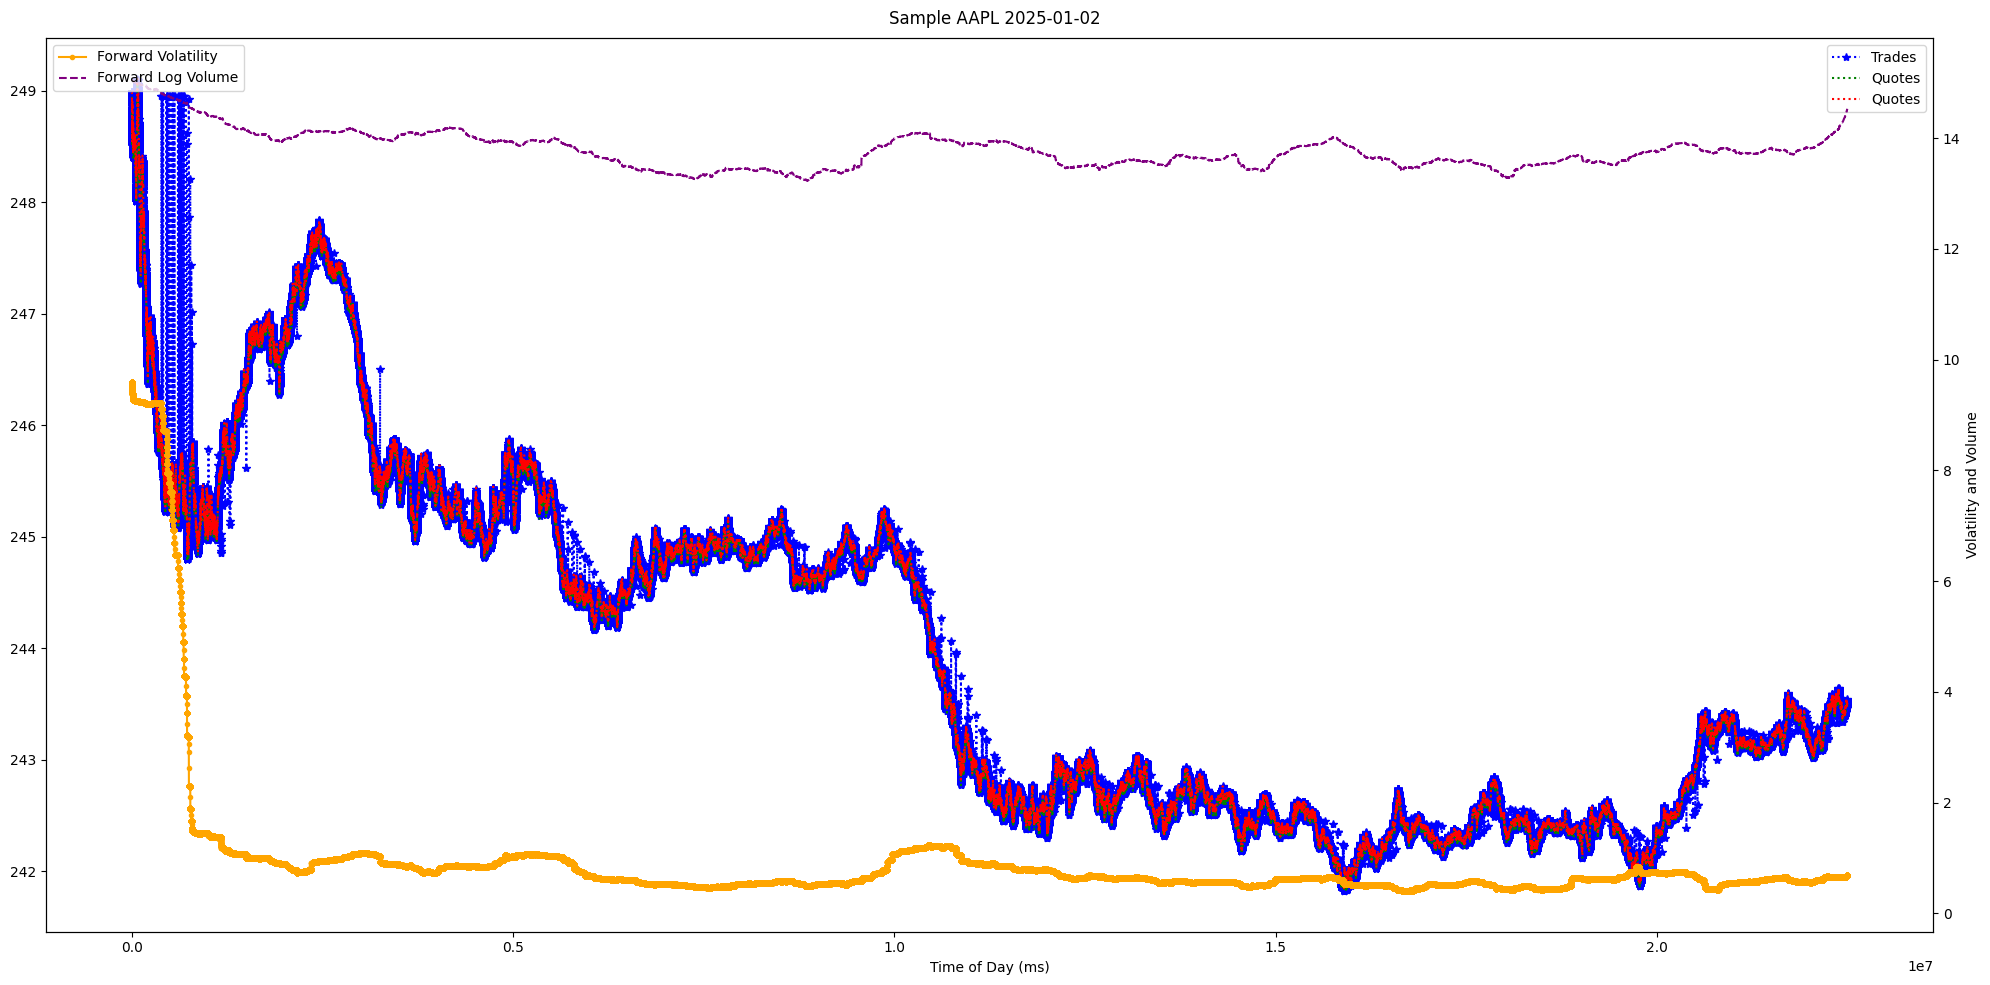

In [4]:
from cdxcore.dynaplot import figure

def visualize_sample( sample_id):
    sample_id = experiment.get_sample_id(sample_id)
    sample    = experiment[sample_id] 

    with figure(f"Sample {sample_id}", row_size=10, col_size=20, columns=None) as fig:
        ax = fig.add_subplot()

        trades  = sample["trades"]
        quotes  = sample["quotes"]
        targets = sample["targets"]

        ax.plot(trades["time_of_day_ms"], trades["price"], "*:", label="Trades", color="blue")
        ax.plot(quotes["time_of_day_ms"], quotes["bid_price"], ":", label="Quotes", color="green")
        ax.plot(quotes["time_of_day_ms"], quotes["ask_price"], ":",  label="Quotes", color="red")

        ax2 = ax.twinx()
        ax2.plot(targets["time_of_day_ms"], targets["volatility"], ".-", label="Forward Volatility", color="orange")
        ax2.plot(targets["time_of_day_ms"], targets["log_volume"], "--", label="Forward Log Volume", color="purple")

        ax.legend(loc="upper right")
        ax.set_xlabel("Time of Day (ms)")
        ax2.legend(loc="upper left")
        ax2.set_ylabel("Volatility and Volume")

visualize_sample(0)


